In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import os
from collections import Counter
import random
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts, OneCycleLR

# Torchvision imports
import torchvision.transforms as T
from torchvision.transforms import functional as TF

# timm for EfficientNetV2
import timm

# Sklearn for cross-validation
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Progress bar
from tqdm.notebook import tqdm

# Set seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Paths
BASE_PATH = Path("bdma-07-competition-2026/BDMA7_project_files")
TRAIN_PATH = BASE_PATH / "train_images"
VAL_PATH = BASE_PATH / "val_images"
TEST_PATH = BASE_PATH / "test_images"

Using device: mps


In [56]:
# ============================================
# Load Metadata & Class Mapping
# ============================================

# Load metadata
train_df = pd.read_csv(BASE_PATH / "train_metadata.csv")
val_df = pd.read_csv(BASE_PATH / "val_metadata.csv")
sample_submission = pd.read_csv(BASE_PATH / "sample_submission.csv")

print(f"Train samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(sample_submission)}")

# Class mapping 
class_mapping = {'Groove_billed_Ani': 0, 'Red_winged_Blackbird': 1, 'Rusty_Blackbird': 2, 'Gray_Catbird': 3, 
                 'Brandt_Cormorant': 4, 'Eastern_Towhee': 5, 'Indigo_Bunting': 6, 'Brewer_Blackbird': 7, 
                 'Painted_Bunting': 8, 'Bobolink': 9, 'Lazuli_Bunting': 10, 'Yellow_headed_Blackbird': 11, 
                 'American_Crow': 12, 'Fish_Crow': 13, 'Brown_Creeper': 14, 'Yellow_billed_Cuckoo': 15, 
                 'Yellow_breasted_Chat': 16, 'Black_billed_Cuckoo': 17, 'Gray_crowned_Rosy_Finch': 18, 'Bronzed_Cowbird': 19}

print(f"Number of classes: {len(class_mapping)}")

Train samples: 1082
Validation samples: 103
Test samples: 400
Number of classes: 20


## Note: Freeze Backbone Always Option

The `freeze_backbone_always` option has been added to the config. When set to `True`:
- The backbone will remain frozen throughout the entire training process
- Only the classifier head will be trained
- Stage 2 (unfreezing) will be skipped
- Training will run for `freeze_backbone_epochs + unfreeze_epochs` epochs, all with frozen backbone

**To use this option:**
1. Set `freeze_backbone_always = True` in the Config class
2. The training function will automatically handle this (code updates needed in training function)

**Benefits:**
- Faster training (only ~353k parameters vs 20M)
- Lower memory usage
- Preserves all pretrained features
- Good for when you have limited data or want to use the model as a feature extractor

In [57]:
# ============================================
# Configuration
# ============================================

class Config:
    # Model
    model_name = 'tf_efficientnetv2_s.in21k_ft_in1k'  # EfficientNetV2-S pretrained on ImageNet
    # model_name = 'tf_efficientnetv2_s.in21k'
    # model_name = 'tf_efficientnetv2_m.in21k_ft_in1k'
    # model_name = 'tf_efficientnetv2_m.in21k'
    # model_name = 'tf_efficientnetv2_l.in21k_ft_in1k'
    # model_name = 'tf_efficientnetv2_l.in21k'

    num_classes = 20
    
    # Transfer Learning Settings
    use_transfer_learning = True  # Enable transfer learning strategy
    freeze_backbone_epochs = 7  # Number of epochs with frozen backbone (train only head)
    unfreeze_epochs = 0  # Number of epochs after unfreezing (fine-tune layers)
    # Total epochs = freeze_backbone_epochs + unfreeze_epochs
    
    # Freeze Backbone Always
    freeze_backbone_always = True  # If True, keep backbone frozen throughout entire training (only train classifier)
    # If True, Stage 2 will be skipped and only classifier head is trained for all epochs
    
    # Progressive Unfreezing Strategy (only used if freeze_backbone_always=False)
    unfreeze_all_layers = False  # If True, unfreeze all layers. If False, use progressive unfreezing
    unfreeze_last_n_blocks = 1  # Number of last blocks/stages to unfreeze (only if unfreeze_all_layers=False)
    # For EfficientNetV2-S: typically has 7 blocks, unfreezing last 2-3 blocks is often optimal
    
    # Training
    batch_size = 16
    learning_rate_head = 1e-3  # Higher LR for classifier head (when backbone frozen)
    learning_rate_backbone = 1e-5  # Lower LR for backbone (when unfrozen)
    weight_decay = 1e-4 # helps prevent overfitting by discouraging large weights in the model.
    
    # K-Fold
    n_folds = 5
    
    # Image settings
    img_size = 384  # EfficientNetV2-S optimal size
    # more experimenting to find the best size is needed (maybe cropping using Deep learning models to fixed size)
    
    # TTA settings
    tta_transforms = 5  # Number of TTA augmentations
    
    # Augmentation settings
    rotation_degrees = 15
    color_jitter = {
        'brightness': 0.2,
        'contrast': 0.2,
        'saturation': 0.2,
        'hue': 0.1
    }
    random_erasing_prob = 0.25
    
    # Early stopping
    patience = 5 # for early stopping when the validation loss is not improving
    
    @property
    def total_epochs(self):
        """Total training epochs"""
        if not self.use_transfer_learning:
            return 15
        elif self.freeze_backbone_always:
            # If always frozen, use freeze_backbone_epochs + unfreeze_epochs (but all with frozen backbone)
            return self.freeze_backbone_epochs + self.unfreeze_epochs
        else:
            # Normal two-stage: freeze epochs + unfreeze epochs
            return self.freeze_backbone_epochs + self.unfreeze_epochs
    
config = Config()
print(f"Model: {config.model_name}")
print(f"Image size: {config.img_size}x{config.img_size}")
print(f"Batch size: {config.batch_size}")
print(f"K-Folds: {config.n_folds}")
print(f"\nTransfer Learning Strategy:")
print(f"  - Enabled: {config.use_transfer_learning}")
if config.use_transfer_learning:
    print(f"  - Freeze backbone always: {config.freeze_backbone_always}")
    if config.freeze_backbone_always:
        print(f"    → Backbone will remain frozen throughout training (classifier only)")
    else:
        print(f"  - Freeze backbone epochs: {config.freeze_backbone_epochs}")
        print(f"  - Unfreeze epochs: {config.unfreeze_epochs}")
        print(f"  - Unfreeze strategy: {'All layers' if config.unfreeze_all_layers else f'Last {config.unfreeze_last_n_blocks} blocks (progressive)'}")
    print(f"  - Total epochs: {config.total_epochs}")
    print(f"  - Head LR: {config.learning_rate_head}")
    print(f"  - Backbone LR: {config.learning_rate_backbone}")

Model: tf_efficientnetv2_s.in21k_ft_in1k
Image size: 384x384
Batch size: 16
K-Folds: 5

Transfer Learning Strategy:
  - Enabled: True
  - Freeze backbone always: True
    → Backbone will remain frozen throughout training (classifier only)
  - Total epochs: 7
  - Head LR: 0.001
  - Backbone LR: 1e-05


In [58]:
# ============================================
# Data Augmentation Transforms
# ============================================

# ImageNet normalization values
# per-channel mean and standard deviation computed from the ImageNet training set (1.2M images).
# Pretrained models expect this normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def get_train_transforms(config):
    """
    Training augmentations:
    - Random resized crop
    - Horizontal flip
    - Color jitter (brightness, contrast, saturation, hue)
    - Random rotation (±15°)
    - Random erasing (Cutout)
    """
    return T.Compose([
        # Random crops and resizes
        T.RandomResizedCrop(
            config.img_size, 
            scale=(0.8, 1.0),
            ratio=(0.9, 1.1)
        ),
        # Horizontal flip
        T.RandomHorizontalFlip(p=0.5),
        # Random rotation ±15°
        T.RandomRotation(degrees=config.rotation_degrees),
        # Color jitter
        T.ColorJitter(
            brightness=config.color_jitter['brightness'],
            contrast=config.color_jitter['contrast'],
            saturation=config.color_jitter['saturation'],
            hue=config.color_jitter['hue']
        ),
        # Convert to tensor
        T.ToTensor(),
        # Normalize
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        # Random erasing (Cutout)
        T.RandomErasing(
            p=config.random_erasing_prob,
            scale=(0.02, 0.2), # The erased area is 2% to 20% of the total image area
            ratio=(0.3, 3.3) # Width/height ratio of the erased rectangle
        )
    ])

def get_val_transforms(config):
    """
    Validation transforms - minimal processing
    Used in the validation set
    """
    return T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def get_tta_transforms(config):
    """
    Test Time Augmentation transforms - multiple variants
    Returns a list of transform pipelines
    Used in the test set
    """
    tta_list = []
    
    # Original (center crop)
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Horizontal flip
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.RandomHorizontalFlip(p=1.0),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Slight rotation +10
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.RandomRotation(degrees=(10, 10)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Slight rotation -10
    tta_list.append(T.Compose([
        T.Resize((config.img_size, config.img_size)),
        T.RandomRotation(degrees=(-10, -10)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    # Center crop with larger resize
    tta_list.append(T.Compose([
        T.Resize(int(config.img_size * 1.1)),
        T.CenterCrop(config.img_size),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]))
    
    return tta_list

print("Transforms defined successfully!")
print(f"Training augmentations: Random crops, H-flip, Rotation ±{config.rotation_degrees}°, Color jitter, Random erasing")
print(f"TTA variants: {len(get_tta_transforms(config))}")

Transforms defined successfully!
Training augmentations: Random crops, H-flip, Rotation ±15°, Color jitter, Random erasing
TTA variants: 5


In [59]:
# ============================================
# Dataset Classes
# ============================================

class BirdsDataset(Dataset):
    """Dataset for bird classification with augmentation support"""
    
    def __init__(self, df, base_path, transform=None):
        self.df = df.reset_index(drop=True)
        self.base_path = Path(base_path)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.base_path / row['path']
        label = row['class_idx']
        
        # Load image
        image = Image.open(img_path).convert('RGB')
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
            
        return image, label


class BirdsTestDataset(Dataset):
    """Dataset for test images (no labels)"""
    
    def __init__(self, image_dir, transform=None):
        self.image_dir = Path(image_dir)
        self.image_files = sorted(list(self.image_dir.glob('*/*.jpg')))
        self.transform = transform
        
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, img_path.name


class TTADataset(Dataset):
    """Dataset wrapper for TTA - returns multiple augmented versions"""
    
    def __init__(self, image_paths, tta_transforms):
        self.image_paths = image_paths
        self.tta_transforms = tta_transforms
        
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        
        # Apply all TTA transforms
        augmented_images = []
        for transform in self.tta_transforms:
            augmented_images.append(transform(image))
            
        return torch.stack(augmented_images), Path(img_path).name

print("Dataset classes defined!")

Dataset classes defined!


In [60]:
# ============================================
# Inspect Model Structure (Diagnostic)
# ============================================

def inspect_model_structure(model):
    """Inspect the model structure to understand classifier head"""
    print("Model Structure Analysis:")
    print("="*60)
    
    # Check classifier/head structure
    if hasattr(model, 'classifier'):
        print(f"\nClassifier found: {type(model.classifier)}")
        print(model.classifier)
    elif hasattr(model, 'head'):
        print(f"\nHead found: {type(model.head)}")
        print(model.head)
    elif hasattr(model, 'fc'):
        print(f"\nFC found: {type(model.fc)}")
        print(model.fc)
    
    # Count parameters by component
    print("\n" + "="*60)
    print("Parameter Breakdown:")
    print("="*60)
    
    classifier_params = 0
    backbone_params = 0
    
    for name, param in model.named_parameters():
        num_params = param.numel()
        if 'classifier' in name or 'head' in name or 'fc' in name:
            classifier_params += num_params
            print(f"  Classifier: {name:50s} {num_params:>12,} params")
        else:
            backbone_params += num_params
    
    print(f"\nTotal Backbone Parameters: {backbone_params:>12,}")
    print(f"Total Classifier Parameters: {classifier_params:>12,}")
    print(f"Total Parameters: {backbone_params + classifier_params:>12,}")
    
    return classifier_params, backbone_params

# Test with a model
print("Inspecting model structure...")
test_model = create_model(config, pretrained=True, freeze_backbone=False)
classifier_params, backbone_params = inspect_model_structure(test_model)

print(f"\n{'='*60}")
print("Expected vs Actual:")
print(f"{'='*60}")
print(f"Frozen backbone should have ~{classifier_params:,} trainable params (classifier only)")
print(f"Unfrozen backbone should have ~{backbone_params + classifier_params:,} trainable params (all)")

del test_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Inspecting model structure...
Model Structure Analysis:

Classifier found: <class 'torch.nn.modules.linear.Linear'>
Linear(in_features=1280, out_features=20, bias=True)

Parameter Breakdown:
  Classifier: conv_head.weight                                        327,680 params
  Classifier: classifier.weight                                        25,600 params
  Classifier: classifier.bias                                              20 params

Total Backbone Parameters:   19,849,808
Total Classifier Parameters:      353,300
Total Parameters:   20,203,108

Expected vs Actual:
Frozen backbone should have ~353,300 trainable params (classifier only)
Unfrozen backbone should have ~20,203,108 trainable params (all)


In [61]:
# ============================================
# Test Progressive Unfreezing (Stage 2)
# ============================================

print("Testing progressive unfreezing (Stage 2 scenario)...")
print("="*60)

# Create model with frozen backbone (like Stage 1)
model_stage2 = create_model(config, pretrained=True, freeze_backbone=True)
print(f"\nAfter Stage 1 (frozen backbone):")
print(f"  Trainable parameters: {get_trainable_params_count(model_stage2):,}")

# Now apply progressive unfreezing (like Stage 2)
print(f"\nApplying progressive unfreezing (last {config.unfreeze_last_n_blocks} blocks)...")
model_stage2 = unfreeze_model_backbone(
    model_stage2, 
    unfreeze_all=config.unfreeze_all_layers,
    last_n_blocks=config.unfreeze_last_n_blocks
)

print(f"\nAfter Stage 2 (progressive unfreezing):")
print(f"  Trainable parameters: {get_trainable_params_count(model_stage2):,}")

# Compare with all unfrozen
model_all_unfrozen = create_model(config, pretrained=True, freeze_backbone=False)
print(f"\nFor comparison (all layers unfrozen):")
print(f"  Trainable parameters: {get_trainable_params_count(model_all_unfrozen):,}")

print(f"\n{'='*60}")
print("Parameter savings with progressive unfreezing:")
savings = get_trainable_params_count(model_all_unfrozen) - get_trainable_params_count(model_stage2)
percentage = (savings / get_trainable_params_count(model_all_unfrozen)) * 100
print(f"  Saved: {savings:,} parameters ({percentage:.1f}% reduction)")

del model_stage2, model_all_unfrozen
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Testing progressive unfreezing (Stage 2 scenario)...

After Stage 1 (frozen backbone):
  Trainable parameters: 353,300

Applying progressive unfreezing (last 1 blocks)...
  Found blocks module: 6 blocks total
  Unfreezing last 1 blocks

After Stage 2 (progressive unfreezing):
  Trainable parameters: 14,915,132

For comparison (all layers unfrozen):
  Trainable parameters: 20,203,108

Parameter savings with progressive unfreezing:
  Saved: 5,287,976 parameters (26.2% reduction)


In [62]:
# ============================================
# Model Definition
# ============================================

def create_model(config, pretrained=True, freeze_backbone=False):
    """
    Create EfficientNetV2-S model with pretrained weights
    and custom classification head for bird species
    
    Args:
        config: Configuration object
        pretrained: Whether to use pretrained weights
        freeze_backbone: If True, freeze all backbone layers (only train classifier head)
    """
    model = timm.create_model(
        config.model_name,
        pretrained=pretrained,
        num_classes=config.num_classes,
        drop_rate=0.3 # dropout
        # drop_path_rate=0.2 
    )
    
    # Freeze backbone if requested
    if freeze_backbone:
        freeze_model_backbone(model)
    
    return model


def freeze_model_backbone(model):
    """
    Freeze all backbone layers, keep only classifier head trainable
    Works with timm models (EfficientNetV2, etc.)
    """
    # For timm models, the classifier is typically named 'classifier' or 'head'
    # Freeze all parameters first
    for param in model.parameters():
        param.requires_grad = False
    
    # Unfreeze only the classifier/head
    # Check common classifier names in timm models
    classifier_names = ['classifier', 'head', 'fc', 'get_classifier']
    
    for name, module in model.named_modules():
        if any(cn in name.lower() for cn in classifier_names):
            for param in module.parameters():
                param.requires_grad = True
    
    # Also check if there's a direct classifier attribute
    if hasattr(model, 'classifier'):
        for param in model.classifier.parameters():
            param.requires_grad = True
    elif hasattr(model, 'head'):
        for param in model.head.parameters():
            param.requires_grad = True
    elif hasattr(model, 'fc'):
        for param in model.fc.parameters():
            param.requires_grad = True
    
    return model


def unfreeze_model_backbone(model, unfreeze_all=True, last_n_blocks=2):
    """
    Unfreeze layers for fine-tuning
    
    Args:
        model: The model to unfreeze
        unfreeze_all: If True, unfreeze all layers. If False, only unfreeze last N blocks
        last_n_blocks: Number of last blocks to unfreeze (only used if unfreeze_all=False)
    """
    if unfreeze_all:
        # Unfreeze all layers
        for param in model.parameters():
            param.requires_grad = True
    else:
        # Progressive unfreezing: only unfreeze last N blocks
        # For EfficientNetV2 models from timm, we need to identify the block structure
        
        # Freeze all parameters first
        for param in model.parameters():
            param.requires_grad = False
        
        # Try multiple strategies to find blocks
        blocks_found = False
        
        # Strategy 1: Look for 'blocks' module (common in EfficientNet)
        if hasattr(model, 'blocks'):
            block_list = list(model.blocks.children())
            total_blocks = len(block_list)
            blocks_to_unfreeze = block_list[-last_n_blocks:] if last_n_blocks > 0 else []
            
            print(f"  Found blocks module: {total_blocks} blocks total")
            print(f"  Unfreezing last {len(blocks_to_unfreeze)} blocks")
            
            # Unfreeze the selected blocks
            for block in blocks_to_unfreeze:
                for param in block.parameters():
                    param.requires_grad = True
            
            blocks_found = True
        
        # Strategy 2: Look for numbered block modules in named_modules
        if not blocks_found:
            # Collect all block-related module names
            block_modules = {}
            for name, module in model.named_modules():
                # Look for patterns like 'blocks.0', 'blocks.1', 'stages.0', etc.
                parts = name.split('.')
                if len(parts) >= 2:
                    try:
                        # Try to extract block index
                        if parts[0] in ['blocks', 'stages', 'layers']:
                            idx = int(parts[1])
                            if parts[0] not in block_modules:
                                block_modules[parts[0]] = []
                            block_modules[parts[0]].append((idx, name))
                    except:
                        pass
            
            if block_modules:
                # Use the first found block structure
                block_type = list(block_modules.keys())[0]
                block_list = sorted(block_modules[block_type], key=lambda x: x[0])
                total_blocks = len(block_list)
                blocks_to_unfreeze = block_list[-last_n_blocks:] if last_n_blocks > 0 else []
                
                print(f"  Found {block_type} structure: {total_blocks} blocks total")
                print(f"  Unfreezing last {len(blocks_to_unfreeze)} blocks: {[idx for idx, _ in blocks_to_unfreeze]}")
                
                # Unfreeze parameters in selected blocks
                for idx, block_name in blocks_to_unfreeze:
                    for name, param in model.named_parameters():
                        if block_name in name:
                            param.requires_grad = True
                
                blocks_found = True
        
        # Strategy 3: Fallback - unfreeze by parameter name patterns (last layers)
        if not blocks_found:
            print("  Using fallback: unfreezing by parameter name patterns")
            
            # Get all parameter names, excluding classifier
            param_names = []
            for name, param in model.named_parameters():
                if 'classifier' not in name and 'head' not in name and 'fc' not in name:
                    param_names.append(name)
            
            if param_names:
                # Estimate: unfreeze roughly last N/7 of parameters (assuming ~7 blocks)
                # This is a heuristic approach
                num_to_unfreeze = max(1, int(len(param_names) * (last_n_blocks / 7.0)))
                params_to_unfreeze = param_names[-num_to_unfreeze:]
                
                print(f"  Unfreezing last {len(params_to_unfreeze)} parameter groups")
                
                for name, param in model.named_parameters():
                    if name in params_to_unfreeze:
                        param.requires_grad = True
        
        # Always unfreeze classifier/head
        for name, param in model.named_parameters():
            if 'classifier' in name or 'head' in name or 'fc' in name:
                param.requires_grad = True
    
    return model


def get_trainable_params_count(model):
    """Get count of trainable parameters"""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Test model creation
print("Testing model creation with transfer learning...")
model_frozen = create_model(config, pretrained=True, freeze_backbone=True)
print(f"\nModel with frozen backbone:")
print(f"  Total parameters: {sum(p.numel() for p in model_frozen.parameters()):,}")
print(f"  Trainable parameters: {get_trainable_params_count(model_frozen):,}")

model_unfrozen = create_model(config, pretrained=True, freeze_backbone=False)
print(f"\nModel with unfrozen backbone:")
print(f"  Total parameters: {sum(p.numel() for p in model_unfrozen.parameters()):,}")
print(f"  Trainable parameters: {get_trainable_params_count(model_unfrozen):,}")

# Clean up test models
del model_frozen, model_unfrozen
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Testing model creation with transfer learning...

Model with frozen backbone:
  Total parameters: 20,203,108
  Trainable parameters: 353,300

Model with unfrozen backbone:
  Total parameters: 20,203,108
  Trainable parameters: 20,203,108


In [63]:
# ============================================
# Training Functions
# ============================================

def train_one_epoch(model, dataloader, criterion, optimizer, scheduler, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(dataloader, desc='Training', leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Update scheduler (for OneCycleLR)
        if scheduler is not None and isinstance(scheduler, OneCycleLR):
            scheduler.step()
        
        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        pbar.set_postfix({'loss': loss.item(), 'acc': 100. * correct / total})
    
    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc


@torch.no_grad()
def validate(model, dataloader, criterion, device):
    """Validate the model"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    
    pbar = tqdm(dataloader, desc='Validation', leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc, np.array(all_preds), np.array(all_labels)


@torch.no_grad()
def validate_with_tta(model, image_paths, tta_transforms, device, batch_size=8):
    """Validate with Test Time Augmentation"""
    model.eval()
    
    dataset = TTADataset(image_paths, tta_transforms)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    
    all_preds = []
    all_filenames = []
    
    pbar = tqdm(dataloader, desc='TTA Inference', leave=False)
    for images_batch, filenames in pbar:
        batch_size_actual = images_batch.size(0)
        n_tta = images_batch.size(1)
        
        # Reshape for batch processing: (batch, n_tta, C, H, W) -> (batch*n_tta, C, H, W)
        images_flat = images_batch.view(-1, *images_batch.shape[2:]).to(device)
        
        # Get predictions
        outputs = model(images_flat)
        probs = torch.softmax(outputs, dim=1)
        
        # Reshape back: (batch*n_tta, num_classes) -> (batch, n_tta, num_classes)
        probs = probs.view(batch_size_actual, n_tta, -1)
        
        # Average predictions across TTA transforms
        avg_probs = probs.mean(dim=1)
        preds = avg_probs.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_filenames.extend(filenames)
    
    return np.array(all_preds), all_filenames

print("Training functions defined!")

Training functions defined!


In [64]:
# ============================================
# Prepare Data for K-Fold Cross Validation
# ============================================

# Combine train and val data paths - we'll use both train and val folders
# Create a unified dataframe with correct paths

# Get all image paths from train folder
train_images_df = train_df.copy()
train_images_df['full_path'] = train_images_df['path'].apply(lambda x: TRAIN_PATH / x)

# Get all image paths from val folder  
val_images_df = val_df.copy()
val_images_df['full_path'] = val_images_df['path'].apply(lambda x: VAL_PATH / x)

# For training, we need to handle that images come from different folders
# Create a combined dataframe with source info
train_images_df['source'] = 'train'
val_images_df['source'] = 'val'

combined_df = pd.concat([train_images_df, val_images_df], ignore_index=True)

print(f"Total training samples: {len(train_images_df)}")
print(f"Total validation samples: {len(val_images_df)}")
print(f"Combined samples for K-Fold: {len(combined_df)}")
print(f"\nClass distribution:")
print(combined_df['class'].value_counts().sort_index())

Total training samples: 1082
Total validation samples: 103
Combined samples for K-Fold: 1185

Class distribution:
class
American_Crow              60
Black_billed_Cuckoo        60
Bobolink                   60
Brandt_Cormorant           59
Brewer_Blackbird           59
Bronzed_Cowbird            60
Brown_Creeper              59
Eastern_Towhee             60
Fish_Crow                  60
Gray_Catbird               59
Gray_crowned_Rosy_Finch    59
Groove_billed_Ani          60
Indigo_Bunting             60
Lazuli_Bunting             58
Painted_Bunting            58
Red_winged_Blackbird       60
Rusty_Blackbird            60
Yellow_billed_Cuckoo       59
Yellow_breasted_Chat       59
Yellow_headed_Blackbird    56
Name: count, dtype: int64


In [65]:
# ============================================
# Custom Dataset for Combined Data
# ============================================

class BirdsCombinedDataset(Dataset):
    """Dataset that handles images from multiple source folders"""
    
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['full_path']
        label = row['class_idx']
        
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, label

print("Combined dataset class defined!")

Combined dataset class defined!


In [ ]:
# ============================================
# K-Fold Cross Validation Training (Fixed for freeze_backbone_always)
# ============================================

def train_kfold(config, combined_df, device):
    """
    Train with K-Fold cross validation
    Returns list of trained models and fold results
    
    Supports three modes:
    1. freeze_backbone_always=True: Train classifier head only for all epochs
    2. Two-stage training: Stage 1 (frozen) + Stage 2 (progressive unfreezing)
    3. No transfer learning: Train all layers from start
    """
    set_seed(42)
    
    # Setup K-Fold
    skf = StratifiedKFold(n_splits=config.n_folds, shuffle=True, random_state=42)
    
    # Get transforms
    train_transforms = get_train_transforms(config)
    val_transforms = get_val_transforms(config)
    
    # Store results
    fold_results = []
    fold_models = []
    
    # Labels for stratified split
    labels = combined_df['class_idx'].values
    
    print("="*60)
    print(f"Starting {config.n_folds}-Fold Cross Validation")
    if config.freeze_backbone_always:
        print("Mode: Backbone Frozen Always (Classifier Only)")
    elif config.use_transfer_learning:
        print("Mode: Two-Stage Transfer Learning")
    else:
        print("Mode: Full Training (All Layers)")
    print("="*60)
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(combined_df, labels)):
        print(f"\n{'='*60}")
        print(f"FOLD {fold + 1}/{config.n_folds}")
        print(f"{'='*60}")
        
        # Split data
        train_fold_df = combined_df.iloc[train_idx]
        val_fold_df = combined_df.iloc[val_idx]
        
        print(f"Train samples: {len(train_fold_df)}, Val samples: {len(val_fold_df)}")
        
        # Create datasets
        train_dataset = BirdsCombinedDataset(train_fold_df, transform=train_transforms)
        val_dataset = BirdsCombinedDataset(val_fold_df, transform=val_transforms)
        
        # Create dataloaders
        train_loader = DataLoader(
            train_dataset, 
            batch_size=config.batch_size, 
            shuffle=True, 
            num_workers=0,
            pin_memory=True if device.type == 'cuda' else False
        )
        val_loader = DataLoader(
            val_dataset, 
            batch_size=config.batch_size, 
            shuffle=False, 
            num_workers=0,
            pin_memory=True if device.type == 'cuda' else False
        )
        
        # Create model with frozen backbone (if using transfer learning)
        if config.use_transfer_learning:
            model = create_model(config, pretrained=True, freeze_backbone=True)
            print(f"Training with frozen backbone")
            print(f"  Trainable parameters: {get_trainable_params_count(model):,}")
        else:
            model = create_model(config, pretrained=True, freeze_backbone=False)
        
        model = model.to(device)
        
        # Loss function with label smoothing
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        
        # Training loop with early stopping
        best_val_acc = 0.0
        best_model_state = None
        patience_counter = 0
        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'stage': []}
        
        total_epochs = config.total_epochs
        
        # ============================================
        # Transfer Learning Training
        # ============================================
        if config.use_transfer_learning:
            # Get only head parameters
            head_params = [p for p in model.parameters() if p.requires_grad]
            
            # Optimizer for head only
            optimizer = optim.AdamW(
                head_params,
                lr=config.learning_rate_head,
                weight_decay=config.weight_decay
            )
            
            # Scheduler
            scheduler = OneCycleLR(
                optimizer,
                max_lr=config.learning_rate_head,
                epochs=total_epochs,
                steps_per_epoch=len(train_loader),
                pct_start=0.1,
                anneal_strategy='cos'
            )
            
            print(f"\n{'='*60}")
            if config.freeze_backbone_always:
                print(f"Training Classifier Head Only (Backbone Always Frozen)")
                print(f"Total Epochs: {total_epochs}")
            else:
                print(f"STAGE 1: Training Classifier Head (Backbone Frozen)")
                print(f"Epochs: {config.freeze_backbone_epochs}")
            print(f"Learning Rate: {config.learning_rate_head}")
            print(f"{'='*60}")
            
            # Stage 1 epochs (or all epochs if freeze_backbone_always)
            stage1_epochs = total_epochs if config.freeze_backbone_always else config.freeze_backbone_epochs
            
            for epoch in range(stage1_epochs):
                if config.freeze_backbone_always:
                    print(f"\nEpoch {epoch + 1}/{total_epochs} [Frozen Backbone]")
                else:
                    print(f"\nEpoch {epoch + 1}/{stage1_epochs} [Stage 1: Frozen Backbone]")
                
                # Train
                train_loss, train_acc = train_one_epoch(
                    model, train_loader, criterion, optimizer, scheduler, device
                )
                
                # Validate
                val_loss, val_acc, val_preds, val_labels = validate(
                    model, val_loader, criterion, device
                )
                
                # Update history
                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['val_loss'].append(val_loss)
                history['val_acc'].append(val_acc)
                history['stage'].append('Frozen')
                
                print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
                print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
                
                # Save best model
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_model_state = model.state_dict().copy()
                    patience_counter = 0
                    print(f"✓ New best model! Val Acc: {val_acc:.2f}%")
                else:
                    patience_counter += 1
                    
                # Early stopping
                if patience_counter >= config.patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break
            
            # ============================================
            # STAGE 2: Progressive Unfreezing (ONLY if not freeze_backbone_always)
            # ============================================
            if not config.freeze_backbone_always and config.unfreeze_epochs > 0:
                print(f"\n{'='*60}")
                if config.unfreeze_all_layers:
                    print(f"STAGE 2: Fine-tuning All Layers (Backbone Unfrozen)")
                else:
                    print(f"STAGE 2: Progressive Fine-tuning (Last {config.unfreeze_last_n_blocks} Blocks)")
                print(f"{'='*60}")
                
                # Unfreeze backbone (progressive or all)
                model = unfreeze_model_backbone(
                    model, 
                    unfreeze_all=config.unfreeze_all_layers,
                    last_n_blocks=config.unfreeze_last_n_blocks
                )
                print(f"  Trainable parameters: {get_trainable_params_count(model):,}")
                
                # Separate backbone and head parameters
                backbone_params = []
                head_params = []
                for name, param in model.named_parameters():
                    if 'classifier' in name or 'fc' in name or 'head' in name:
                        head_params.append(param)
                    else:
                        backbone_params.append(param)
                
                # New optimizer with different LRs for backbone and head
                optimizer = optim.AdamW([
                    {'params': backbone_params, 'lr': config.learning_rate_backbone},
                    {'params': head_params, 'lr': config.learning_rate_head * 0.1}
                ], weight_decay=config.weight_decay)
                
                # New scheduler for Stage 2
                scheduler = OneCycleLR(
                    optimizer,
                    max_lr=[config.learning_rate_backbone, config.learning_rate_head * 0.1],
                    epochs=config.unfreeze_epochs,
                    steps_per_epoch=len(train_loader),
                    pct_start=0.1,
                    anneal_strategy='cos'
                )
                
                print(f"Epochs: {config.unfreeze_epochs}")
                print(f"Backbone LR: {config.learning_rate_backbone}")
                print(f"Head LR: {config.learning_rate_head * 0.1}")
                
                # Reset patience counter for Stage 2
                patience_counter = 0
                
                for epoch in range(config.unfreeze_epochs):
                    global_epoch = config.freeze_backbone_epochs + epoch + 1
                    print(f"\nEpoch {global_epoch}/{total_epochs} [Stage 2: Fine-tuning]")
                    
                    # Train
                    train_loss, train_acc = train_one_epoch(
                        model, train_loader, criterion, optimizer, scheduler, device
                    )
                    
                    # Validate
                    val_loss, val_acc, val_preds, val_labels = validate(
                        model, val_loader, criterion, device
                    )
                    
                    # Update history
                    history['train_loss'].append(train_loss)
                    history['train_acc'].append(train_acc)
                    history['val_loss'].append(val_loss)
                    history['val_acc'].append(val_acc)
                    history['stage'].append('Fine-tune')
                    
                    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
                    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
                    
                    # Save best model
                    if val_acc > best_val_acc:
                        best_val_acc = val_acc
                        best_model_state = model.state_dict().copy()
                        patience_counter = 0
                        print(f"✓ New best model! Val Acc: {val_acc:.2f}%")
                    else:
                        patience_counter += 1
                        
                    # Early stopping
                    if patience_counter >= config.patience:
                        print(f"Early stopping at epoch {global_epoch}")
                        break
            elif config.freeze_backbone_always:
                print(f"\n{'='*60}")
                print(f"Training complete - Backbone remained frozen throughout")
                print(f"{'='*60}")
        
        else:
            # Original training without transfer learning strategy
            backbone_params = []
            head_params = []
            for name, param in model.named_parameters():
                if 'classifier' in name or 'fc' in name or 'head' in name:
                    head_params.append(param)
                else:
                    backbone_params.append(param)
            
            optimizer = optim.AdamW([
                {'params': backbone_params, 'lr': config.learning_rate_backbone},
                {'params': head_params, 'lr': config.learning_rate_head}
            ], weight_decay=config.weight_decay)
            
            scheduler = OneCycleLR(
                optimizer,
                max_lr=[config.learning_rate_backbone, config.learning_rate_head],
                epochs=total_epochs,
                steps_per_epoch=len(train_loader),
                pct_start=0.1,
                anneal_strategy='cos'
            )
            
            for epoch in range(total_epochs):
                print(f"\nEpoch {epoch + 1}/{total_epochs}")
                
                train_loss, train_acc = train_one_epoch(
                    model, train_loader, criterion, optimizer, scheduler, device
                )
                
                val_loss, val_acc, val_preds, val_labels = validate(
                    model, val_loader, criterion, device
                )
                
                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['val_loss'].append(val_loss)
                history['val_acc'].append(val_acc)
                history['stage'].append('Full')
                
                print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
                print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")
                
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_model_state = model.state_dict().copy()
                    patience_counter = 0
                    print(f"✓ New best model! Val Acc: {val_acc:.2f}%")
                else:
                    patience_counter += 1
                    
                if patience_counter >= config.patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break
        
        # Load best model state
        model.load_state_dict(best_model_state)
        
        # Store results
        fold_results.append({
            'fold': fold + 1,
            'best_val_acc': best_val_acc,
            'history': history,
            'val_idx': val_idx
        })
        fold_models.append(model)
        
        print(f"\nFold {fold + 1} Best Validation Accuracy: {best_val_acc:.2f}%")
        
        # Clean up
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
    
    # Print summary
    print("\n" + "="*60)
    print("K-FOLD CROSS VALIDATION SUMMARY")
    print("="*60)
    
    accuracies = [r['best_val_acc'] for r in fold_results]
    print(f"Fold Accuracies: {[f'{acc:.2f}%' for acc in accuracies]}")
    print(f"Mean Accuracy: {np.mean(accuracies):.2f}% ± {np.std(accuracies):.2f}%")
    
    return fold_models, fold_results

print("K-Fold training function defined.")

K-Fold training function defined (fixed for freeze_backbone_always)!


In [67]:
# ============================================
# RUN K-FOLD TRAINING
# ============================================

# Train all folds
fold_models, fold_results = train_kfold(config, combined_df, device)

Starting 5-Fold Cross Validation
Mode: Backbone Frozen Always (Classifier Only)

FOLD 1/5
Train samples: 948, Val samples: 237
Training with frozen backbone
  Trainable parameters: 353,300

Training Classifier Head Only (Backbone Always Frozen)
Total Epochs: 7
Learning Rate: 0.001

Epoch 1/7 [Frozen Backbone]


Training:   0%|          | 0/60 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

Train Loss: 5.8100, Train Acc: 16.35%
Val Loss: 2.1062, Val Acc: 58.23%
✓ New best model! Val Acc: 58.23%

Epoch 2/7 [Frozen Backbone]


Training:   0%|          | 0/60 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

... (96 outputs left out)

Train Loss: 1.7099, Train Acc: 79.01%
Val Loss: 1.4031, Val Acc: 81.43%

Epoch 7/7 [Frozen Backbone]


Training:   0%|          | 0/60 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

Train Loss: 1.6300, Train Acc: 81.12%
Val Loss: 1.4277, Val Acc: 81.01%

Training complete - Backbone remained frozen throughout

Fold 5 Best Validation Accuracy: 81.43%

K-FOLD CROSS VALIDATION SUMMARY
Fold Accuracies: ['78.48%', '83.12%', '83.97%', '86.08%', '81.43%']
Mean Accuracy: 82.62% ± 2.55%


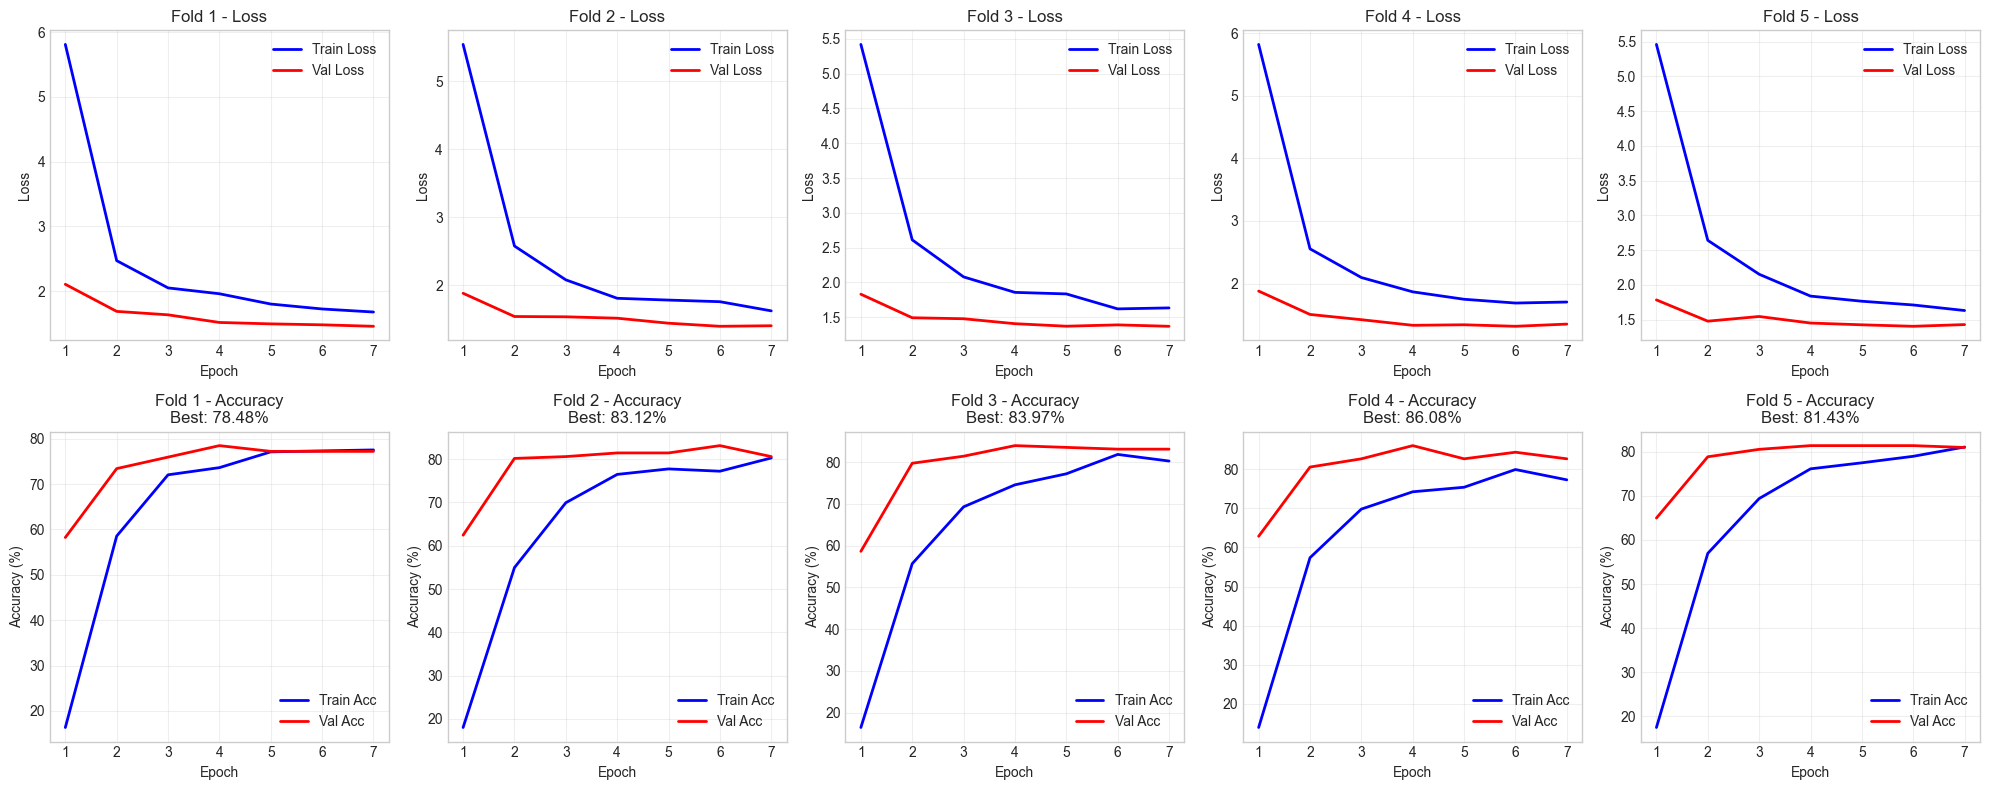

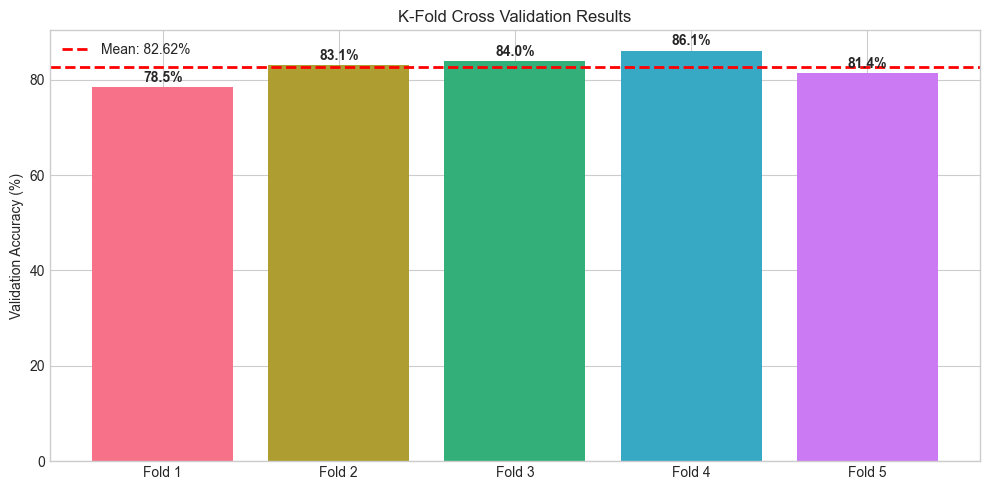

In [68]:
# ============================================
# Visualize Training Results
# ============================================

def plot_training_history(fold_results):
    """Plot training history for all folds"""
    n_folds = len(fold_results)
    
    fig, axes = plt.subplots(2, n_folds, figsize=(4*n_folds, 8))
    
    for fold_idx, result in enumerate(fold_results):
        history = result['history']
        epochs = range(1, len(history['train_loss']) + 1)
        
        # Loss plot
        ax_loss = axes[0, fold_idx] if n_folds > 1 else axes[0]
        ax_loss.plot(epochs, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
        ax_loss.plot(epochs, history['val_loss'], 'r-', label='Val Loss', linewidth=2)
        ax_loss.set_xlabel('Epoch')
        ax_loss.set_ylabel('Loss')
        ax_loss.set_title(f'Fold {fold_idx + 1} - Loss')
        ax_loss.legend()
        ax_loss.grid(True, alpha=0.3)
        
        # Accuracy plot
        ax_acc = axes[1, fold_idx] if n_folds > 1 else axes[1]
        ax_acc.plot(epochs, history['train_acc'], 'b-', label='Train Acc', linewidth=2)
        ax_acc.plot(epochs, history['val_acc'], 'r-', label='Val Acc', linewidth=2)
        ax_acc.set_xlabel('Epoch')
        ax_acc.set_ylabel('Accuracy (%)')
        ax_acc.set_title(f'Fold {fold_idx + 1} - Accuracy\nBest: {result["best_val_acc"]:.2f}%')
        ax_acc.legend()
        ax_acc.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Summary bar chart
    fig, ax = plt.subplots(figsize=(10, 5))
    folds = [f'Fold {r["fold"]}' for r in fold_results]
    accuracies = [r['best_val_acc'] for r in fold_results]
    
    bars = ax.bar(folds, accuracies, color=sns.color_palette("husl", n_folds))
    ax.axhline(y=np.mean(accuracies), color='red', linestyle='--', 
               label=f'Mean: {np.mean(accuracies):.2f}%', linewidth=2)
    ax.set_ylabel('Validation Accuracy (%)')
    ax.set_title('K-Fold Cross Validation Results')
    ax.legend()
    
    # Add value labels on bars
    for bar, acc in zip(bars, accuracies):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('kfold_results.png', dpi=150, bbox_inches='tight')
    plt.show()

# Plot results
plot_training_history(fold_results)

In [69]:
# ============================================
# Test Inference with TTA and Model Ensemble
# ============================================

@torch.no_grad()
def predict_with_tta_ensemble(models, test_dir, config, device):
    """
    Make predictions on test set using:
    1. Ensemble of K-fold models
    2. Test Time Augmentation for each model
    """
    # Get TTA transforms
    tta_transforms = get_tta_transforms(config)
    n_tta = len(tta_transforms)
    n_models = len(models)
    
    # Get test image paths
    test_dir = Path(test_dir)
    test_images = sorted(list(test_dir.glob('*/*.jpg')))
    
    print(f"Test images found: {len(test_images)}")
    print(f"Models in ensemble: {n_models}")
    print(f"TTA variants: {n_tta}")
    print(f"Total predictions per image: {n_models * n_tta}")
    
    all_predictions = []
    all_filenames = []
    
    # Set all models to eval mode
    for model in models:
        model.eval()
    
    pbar = tqdm(test_images, desc='Predicting with TTA Ensemble')
    
    for img_path in pbar:
        image = Image.open(img_path).convert('RGB')
        
        # Collect predictions from all models and all TTA variants
        ensemble_probs = []
        
        for model in models:
            model_probs = []
            
            for transform in tta_transforms:
                img_tensor = transform(image).unsqueeze(0).to(device)
                output = model(img_tensor)
                probs = torch.softmax(output, dim=1)
                model_probs.append(probs.cpu())
            
            # Average across TTA for this model
            model_avg_probs = torch.stack(model_probs).mean(dim=0)
            ensemble_probs.append(model_avg_probs)
        
        # Average across all models
        final_probs = torch.stack(ensemble_probs).mean(dim=0)
        pred = final_probs.argmax(dim=1).item()
        
        all_predictions.append(pred)
        all_filenames.append(img_path.name)
    
    return all_predictions, all_filenames

print("TTA Ensemble inference function defined!")

TTA Ensemble inference function defined!


In [70]:
# ============================================
# Generate Predictions on Test Set
# ============================================

# Run TTA ensemble prediction
predictions, filenames = predict_with_tta_ensemble(
    fold_models, 
    TEST_PATH, 
    config, 
    device
)

print(f"\nPredictions generated for {len(predictions)} images")

Test images found: 400
Models in ensemble: 5
TTA variants: 5
Total predictions per image: 25


Predicting with TTA Ensemble:   0%|          | 0/400 [00:00<?, ?it/s]


Predictions generated for 400 images


In [74]:
# ============================================
# Create Submission File
# ============================================

# IMPORTANT: Submission format must match sample_submission.csv
# Column 1: 'path' (the image filename)
# Column 2: 'class_idx' (the numeric class index, NOT class name)

# Create submission dataframe with correct format
submission_df = pd.DataFrame({
    'path': filenames,           # First column: path (image filename)
    'class_idx': predictions      # Second column: class_idx (numeric prediction)
})

# Sort by path to match sample submission format
submission_df = submission_df.sort_values('path').reset_index(drop=True)

# Display sample
print("Submission Preview (correct format: path, class_idx):")
print(submission_df.head(10))

print(f"\nClass index distribution in predictions:")
print(submission_df['class_idx'].value_counts().sort_index())

# Verify format matches sample submission
print(f"\nSubmission columns: {list(submission_df.columns)}")
print(f"Expected columns: ['path', 'class_idx']")

# ============================================
# Generate organized submission folder structure
# ============================================
import os
from datetime import datetime

# Extract model name (short version)
model_short = config.model_name.split('.')[-1].replace('_', '-')  # e.g., 'in21k-ft-in1k'
model_base = config.model_name.split('.')[0].replace('_', '')  # e.g., 'tfefficientnetv2s'
model_arch = config.model_name.split('.')[0].replace('tf_', '').replace('_', '')  # e.g., 'efficientnetv2s'

# Determine training mode
if config.freeze_backbone_always:
    train_mode = 'frozen-always'
elif config.use_transfer_learning:
    if config.unfreeze_all_layers:
        train_mode = 'tl-all-unfrozen'
    else:
        train_mode = f'tl-last{config.unfreeze_last_n_blocks}blocks'
else:
    train_mode = 'full-training'

# Build experiment folder name (same as models)
experiment_parts = [
    f'img{config.img_size}',                       # Image size
    f'{config.n_folds}fold',                       # Number of folds
    train_mode,                                    # Training mode
    f'ep{config.total_epochs}',                    # Total epochs
    f'tta{len(get_tta_transforms(config))}',       # TTA variants
    datetime.now().strftime('%Y%m%d_%H%M')         # Timestamp
]
experiment_name = '_'.join(experiment_parts)

# Create folder structure: submissions/<model_arch>/<experiment_name>/
submissions_base_dir = 'submissions'
model_arch_dir = os.path.join(submissions_base_dir, model_arch)
experiment_dir = os.path.join(model_arch_dir, experiment_name)

os.makedirs(experiment_dir, exist_ok=True)

# Build filename
submission_filename = 'submission.csv'
submission_path = os.path.join(experiment_dir, submission_filename)

# Save submission
submission_df.to_csv(submission_path, index=False)

# Also save a copy of the config for reference
config_info = {
    'model_name': config.model_name,
    'num_classes': config.num_classes,
    'img_size': config.img_size,
    'batch_size': config.batch_size,
    'use_transfer_learning': config.use_transfer_learning,
    'freeze_backbone_always': config.freeze_backbone_always,
    'freeze_backbone_epochs': config.freeze_backbone_epochs,
    'unfreeze_epochs': config.unfreeze_epochs,
    'unfreeze_all_layers': config.unfreeze_all_layers,
    'unfreeze_last_n_blocks': config.unfreeze_last_n_blocks,
    'learning_rate_head': config.learning_rate_head,
    'learning_rate_backbone': config.learning_rate_backbone,
    'weight_decay': config.weight_decay,
    'n_folds': config.n_folds,
    'total_epochs': config.total_epochs,
    'tta_variants': len(get_tta_transforms(config)),
    'train_mode': train_mode,
    'mean_val_accuracy': np.mean([r['best_val_acc'] for r in fold_results]),
    'std_val_accuracy': np.std([r['best_val_acc'] for r in fold_results]),
    'fold_accuracies': [r['best_val_acc'] for r in fold_results]
}

# Save config as JSON
import json
config_path = os.path.join(experiment_dir, 'experiment_config.json')
with open(config_path, 'w') as f:
    json.dump(config_info, f, indent=2)

print(f"\n{'='*60}")
print(f"Submission Directory Structure:")
print(f"{'='*60}")
print(f"  Base: {submissions_base_dir}/")
print(f"  └── Architecture: {model_arch}/")
print(f"      └── Experiment: {experiment_name}/")
print(f"          ├── submission.csv")
print(f"          └── experiment_config.json")

print(f"\n{'='*60}")
print(f"Submission Details:")
print(f"{'='*60}")
print(f"  Model: {config.model_name}")
print(f"  Image Size: {config.img_size}x{config.img_size}")
print(f"  K-Folds: {config.n_folds}")
print(f"  Training Mode: {train_mode}")
print(f"  Total Epochs: {config.total_epochs}")
print(f"  TTA Variants: {len(get_tta_transforms(config))}")
print(f"  Mean Val Accuracy: {config_info['mean_val_accuracy']:.2f}% ± {config_info['std_val_accuracy']:.2f}%")
print(f"\n✓ Submission saved to: {submission_path}")
print(f"✓ Config saved to: {config_path}")

Submission Preview (correct format: path, class_idx):
                                       path  class_idx
0  000c02a0-3687-4c0c-bdfc-394b56134ac6.jpg         13
1  0036f660-7d6e-46d4-822d-dbb71b20c788.jpg         19
2  0082f891-33f6-4057-aa63-c2f462ea66a5.jpg         15
3  01e21934-d737-4992-b712-cf544666bd54.jpg         12
4  0321cf4c-2a19-42b5-992c-f1d6d80af4c7.jpg          3
5  03b3a4cf-dccc-4874-bf30-809e5498a815.jpg         16
6  04ad8917-07dc-451a-a59c-f4fc8827e0ab.jpg          7
7  054c4510-d3a2-4b20-976e-2cf93f78ec81.jpg         12
8  05d54ffe-c3ef-41c8-94eb-44bdd2c77311.jpg         10
9  061c3569-07a0-4611-ad18-ffeec09fb828.jpg          2

Class index distribution in predictions:
class_idx
0     22
1     15
2     22
3     17
4     20
5     17
6     15
7     17
8     14
9     33
10    20
11    19
12    11
13    21
14    19
15    21
16    18
17    37
18    24
19    18
Name: count, dtype: int64

Submission columns: ['path', 'class_idx']
Expected columns: ['path', 'class_idx']


In [75]:
# ============================================
# Save Models (Organized Folder Structure)
# ============================================

import os
from datetime import datetime

# ============================================
# Generate organized folder structure
# ============================================

# Main model folder (architecture name)
model_arch = config.model_name.split('.')[0].replace('tf_', '').replace('_', '')  # e.g., 'efficientnetv2s'

# Determine training mode for subfolder naming
if config.freeze_backbone_always:
    train_mode = 'frozen-always'
elif config.use_transfer_learning:
    if config.unfreeze_all_layers:
        train_mode = 'tl-all-unfrozen'
    else:
        train_mode = f'tl-last{config.unfreeze_last_n_blocks}blocks'
else:
    train_mode = 'full-training'

# Build experiment subfolder name
experiment_parts = [
    f'img{config.img_size}',                       # Image size
    f'{config.n_folds}fold',                       # Number of folds
    train_mode,                                    # Training mode
    f'ep{config.total_epochs}',                    # Total epochs
    f'tta{len(get_tta_transforms(config))}',       # TTA variants
    datetime.now().strftime('%Y%m%d_%H%M')         # Timestamp
]
experiment_name = '_'.join(experiment_parts)

# Create folder structure: models/<model_arch>/<experiment_name>/
models_base_dir = 'models'
model_arch_dir = os.path.join(models_base_dir, model_arch)
experiment_dir = os.path.join(model_arch_dir, experiment_name)

os.makedirs(experiment_dir, exist_ok=True)

print(f"{'='*60}")
print(f"Model Save Directory Structure:")
print(f"{'='*60}")
print(f"  Base: {models_base_dir}/")
print(f"  └── Architecture: {model_arch}/")
print(f"      └── Experiment: {experiment_name}/")
print(f"{'='*60}")

# Save each fold model
for fold_idx, model in enumerate(fold_models):
    model_filename = f'fold{fold_idx + 1}.pth'
    model_path = os.path.join(experiment_dir, model_filename)
    
    # Save comprehensive checkpoint
    torch.save({
        'model_state_dict': model.state_dict(),
        'config': {
            'model_name': config.model_name,
            'num_classes': config.num_classes,
            'img_size': config.img_size,
            'batch_size': config.batch_size,
            'use_transfer_learning': config.use_transfer_learning,
            'freeze_backbone_always': config.freeze_backbone_always,
            'freeze_backbone_epochs': config.freeze_backbone_epochs,
            'unfreeze_epochs': config.unfreeze_epochs,
            'unfreeze_all_layers': config.unfreeze_all_layers,
            'unfreeze_last_n_blocks': config.unfreeze_last_n_blocks,
            'learning_rate_head': config.learning_rate_head,
            'learning_rate_backbone': config.learning_rate_backbone,
            'weight_decay': config.weight_decay,
            'n_folds': config.n_folds,
            'total_epochs': config.total_epochs
        },
        'class_mapping': class_mapping,
        'fold': fold_idx + 1,
        'val_acc': fold_results[fold_idx]['best_val_acc'],
        'history': fold_results[fold_idx]['history']
    }, model_path)
    print(f"✓ Saved: {model_path} (Val Acc: {fold_results[fold_idx]['best_val_acc']:.2f}%)")

# Calculate mean accuracy
mean_acc = np.mean([r['best_val_acc'] for r in fold_results])
std_acc = np.std([r['best_val_acc'] for r in fold_results])

print(f"\n{'='*60}")
print(f"Summary:")
print(f"{'='*60}")
print(f"  Models saved: {len(fold_models)}")
print(f"  Location: {experiment_dir}/")
print(f"  Mean Accuracy: {mean_acc:.2f}% ± {std_acc:.2f}%")
print(f"{'='*60}")

Model Save Directory Structure:
  Base: models/
  └── Architecture: efficientnetv2s/
      └── Experiment: img384_5fold_frozen-always_ep7_tta5_20260126_0109/
✓ Saved: models/efficientnetv2s/img384_5fold_frozen-always_ep7_tta5_20260126_0109/fold1.pth (Val Acc: 78.48%)
✓ Saved: models/efficientnetv2s/img384_5fold_frozen-always_ep7_tta5_20260126_0109/fold2.pth (Val Acc: 83.12%)
✓ Saved: models/efficientnetv2s/img384_5fold_frozen-always_ep7_tta5_20260126_0109/fold3.pth (Val Acc: 83.97%)
✓ Saved: models/efficientnetv2s/img384_5fold_frozen-always_ep7_tta5_20260126_0109/fold4.pth (Val Acc: 86.08%)
✓ Saved: models/efficientnetv2s/img384_5fold_frozen-always_ep7_tta5_20260126_0109/fold5.pth (Val Acc: 81.43%)

Summary:
  Models saved: 5
  Location: models/efficientnetv2s/img384_5fold_frozen-always_ep7_tta5_20260126_0109/
  Mean Accuracy: 82.62% ± 2.55%


In [ ]:
# ============================================
# Utility: Load Saved Models (Updated for new folder structure)
# ============================================

def list_available_experiments(models_base_dir='models'):
    """List all available experiment folders"""
    models_base = Path(models_base_dir)
    
    if not models_base.exists():
        print(f"No models directory found at: {models_base_dir}")
        return []
    
    experiments = []
    print(f"{'='*70}")
    print(f"Available Experiments:")
    print(f"{'='*70}")
    
    # Iterate through model architectures
    for arch_dir in sorted(models_base.iterdir()):
        if arch_dir.is_dir():
            print(f"\n📁 {arch_dir.name}/")
            
            # Iterate through experiments
            for exp_dir in sorted(arch_dir.iterdir()):
                if exp_dir.is_dir():
                    # Count fold files
                    fold_files = list(exp_dir.glob('fold*.pth'))
                    
                    # Try to get accuracy from first fold
                    acc_str = ""
                    if fold_files:
                        try:
                            checkpoint = torch.load(fold_files[0], map_location='cpu')
                            acc_str = f" (Val Acc: {checkpoint['val_acc']:.2f}%)"
                        except:
                            pass
                    
                    print(f"   └── 📂 {exp_dir.name}/ [{len(fold_files)} folds]{acc_str}")
                    experiments.append(str(exp_dir))
    
    print(f"\n{'='*70}")
    return experiments


def load_saved_models(experiment_dir, device=device):
    """
    Load all saved fold models from an experiment directory
    
    Args:
        experiment_dir: Path to experiment folder (e.g., 'models/efficientnetv2s/img384_5fold_frozen-always_ep15_tta5_20260126_1430')
        device: Device to load models on
    
    Returns:
        List of loaded models
    """
    experiment_path = Path(experiment_dir)
    
    if not experiment_path.exists():
        raise FileNotFoundError(f"Experiment directory not found: {experiment_dir}")
    
    # Find all fold files
    model_files = sorted(experiment_path.glob('fold*.pth'))
    
    if not model_files:
        raise FileNotFoundError(f"No fold*.pth files found in: {experiment_dir}")
    
    loaded_models = []
    
    print(f"{'='*60}")
    print(f"Loading models from: {experiment_dir}")
    print(f"{'='*60}")
    
    for model_path in model_files:
        checkpoint = torch.load(model_path, map_location=device)
        
        # Create model
        model = timm.create_model(
            checkpoint['config']['model_name'],
            pretrained=False,
            num_classes=checkpoint['config']['num_classes']
        )
        
        # Load weights
        model.load_state_dict(checkpoint['model_state_dict'])
        model = model.to(device)
        model.eval()
        
        loaded_models.append(model)
        print(f"✓ Loaded: {model_path.name} (Fold {checkpoint['fold']}, Val Acc: {checkpoint['val_acc']:.2f}%)")
    
    # Print experiment config
    print(f"\n{'='*60}")
    print(f"Experiment Config:")
    print(f"{'='*60}")
    config_info = checkpoint['config']
    print(f"  Model: {config_info['model_name']}")
    print(f"  Image Size: {config_info['img_size']}x{config_info['img_size']}")
    print(f"  Transfer Learning: {config_info.get('use_transfer_learning', 'N/A')}")
    print(f"  Freeze Backbone Always: {config_info.get('freeze_backbone_always', 'N/A')}")
    print(f"  Total Epochs: {config_info.get('total_epochs', 'N/A')}")
    print(f"{'='*60}")
    
    return loaded_models


# Example usage:
print("Utility functions defined!")
print("\nUsage:")
print("  1. List experiments:    list_available_experiments('models')")
print("  2. Load models:         loaded_models = load_saved_models('models/efficientnetv2s/img384_5fold_...')")
print("  3. Run predictions:     predictions, filenames = predict_with_tta_ensemble(loaded_models, TEST_PATH, config, device)")

# Summary

## Experiment Configuration
- **Model**: EfficientNetV2-S (pretrained on ImageNet-21K, fine-tuned on ImageNet-1K)
- **Cross-Validation**: 5-Fold Stratified K-Fold
- **Image Size**: 384×384
- **Batch Size**: 16

## Transfer Learning Strategy
- **Two-Stage Training**:
  1. **Stage 1 (Frozen Backbone)**: Train classifier head only for 5 epochs
     - Learning Rate: 1e-3 (higher for new head)
     - Only classifier parameters are trainable
  2. **Stage 2 (Fine-tuning)**: Progressive unfreezing for 10 epochs
     - **Progressive Unfreezing** (default): Only unfreeze last 2 blocks + classifier
       - Preserves early layers (general features like edges, textures)
       - Fine-tunes later layers (task-specific features)
       - More stable and computationally efficient
     - **Alternative**: Can unfreeze all layers if `unfreeze_all_layers=True`
     - Backbone LR: 1e-5 (lower to preserve pretrained features)
     - Head LR: 1e-4 (reduced from Stage 1)
- **Total Epochs**: 15 per fold (with early stopping, patience=5)

## Data Augmentation (Training)
- Random Resized Crop (scale 0.8-1.0)
- Random Horizontal Flip (p=0.5)
- Random Rotation (±15°)
- Color Jitter (brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1)
- Random Erasing/Cutout (p=0.25)

## Test Time Augmentation (TTA)
- Original image
- Horizontal flip
- +10° rotation
- -10° rotation
- Center crop from 1.1× resize

## Ensemble Strategy
- Soft voting across all K-fold models
- Probability averaging across TTA variants
- Final prediction: argmax of averaged probabilities

In [ ]:
# ============================================
# Visualize Sample Augmentations (Optional)
# ============================================

def visualize_augmentations(image_path, config, n_samples=5):
    """Visualize different augmentations applied to a single image"""
    train_transforms = get_train_transforms(config)
    
    image = Image.open(image_path).convert('RGB')
    
    fig, axes = plt.subplots(1, n_samples + 1, figsize=(3*(n_samples+1), 3))
    
    # Original
    axes[0].imshow(image)
    axes[0].set_title('Original')
    axes[0].axis('off')
    
    # Augmented versions
    for i in range(n_samples):
        aug_tensor = train_transforms(image)
        # Denormalize for visualization
        aug_img = aug_tensor.permute(1, 2, 0).numpy()
        aug_img = aug_img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
        aug_img = np.clip(aug_img, 0, 1)
        
        axes[i+1].imshow(aug_img)
        axes[i+1].set_title(f'Aug {i+1}')
        axes[i+1].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example: visualize augmentations on a sample image
sample_image = list(TRAIN_PATH.glob('*/*.jpg'))[0]
visualize_augmentations(sample_image, config)

In [ ]:
# ============================================
# Confusion Matrix Visualization (Optional)
# ============================================

def plot_confusion_matrix(y_true, y_pred, class_names):
    """Plot confusion matrix"""
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(14, 12))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

# This can be called after validation if you have true labels
# class_names = list(class_mapping.keys())
# plot_confusion_matrix(val_labels, val_preds, class_names)

,path,class,class_idx
0,Brandt_Cormorant/Brandt_Cormorant_0071_23007.jpg,Brandt_Cormorant,4
1,Brandt_Cormorant/Brandt_Cormorant_0028_22892.jpg,Brandt_Cormorant,4
